# Where New York's ride-hail riders wait too long

**The scenario.** A ride-hail marketplace team in New York has a fixed monthly budget for
driver incentives and one question: where, and when, should it be spent to cut long waits?
The team is hypothetical. The data is not: every Uber and Lyft trip in New York City in
June 2026, 20.8 million of them, from the Taxi and Limousine Commission.

**The answer.** Concentrate it. A tenth of the city's zone-hours produce 44% of all long
waits, mostly late at night and at the airports on weekday evenings. And spend it on getting
drivers *there*, not on the ride: 92% of a long wait is the driver still on the way.

This notebook follows the argument. The SQL that produces each table is in `sql/`, and
`validate.py` checks every figure quoted here.

In [1]:
import pandas as pd
from IPython.display import Image, display

pd.set_option("display.float_format", "{:,.2f}".format)
read = lambda name: pd.read_csv(f"outputs/{name}.csv")

## 1. What was kept

Scheduled rides show up as pickups *before* the request, at almost the same rate for both
companies, and are removed because their wait is not a wait. See `CLEANING_LOG.md`.

In [2]:
read("cleaning_audit").T.rename(columns={0: "rows"})

,rows
raw_trips,20775868
unknown_zone,1241
missing_time,0
negative_wait,260881
wait_over_60,954
kept,20512792


In [3]:
read("negative_by_operator")

,operator,trips,negative_wait,negative_pct,median_minutes_early
0,Uber,15256807,185220,1.21,6.10
1,Lyft,5517820,75661,1.37,6.40


## 2. How long do people wait?

Most rides are quick. The median wait is under five minutes. But one ride in eight waits
more than ten, which across a month is 2.5 million rides.

In [4]:
read("headline")

,trips,long_waits,long_wait_pct,median_wait_min,p90_wait_min
0,20512792,2470360,12.00,4.80,10.75


In [5]:
read("by_operator")

,operator,trips,share_of_trips_pct,long_wait_pct
0,Uber,15070786,73.50,13.60
1,Lyft,5442006,26.50,7.70


Uber rides wait long far more often than Lyft rides. That could be service, or it could
be that the two companies record the request time differently. The data cannot tell those
apart, so everything below treats the market as one.

## 3. When and where?

**Not a borough problem.** No borough owns it: each of the four big ones holds between 16%
and 28% of long waits, and Manhattan, with a third of all rides, holds less than its share.
A borough-level scheme would spend money everywhere.

In [6]:
read("by_borough")

,borough,trips,share_of_trips_pct,share_of_long_waits_pct,long_wait_pct
0,Brooklyn,5653528,27.60,28.20,12.30
1,Manhattan,7046473,34.40,27.90,9.80
2,Queens,4712964,23.00,25.90,13.60
3,Bronx,2760863,13.50,15.70,14.00
4,Staten Island,338964,1.70,2.30,17.00


**A time problem.** The long-wait rate is 21% at 4am and 6% at 10am.

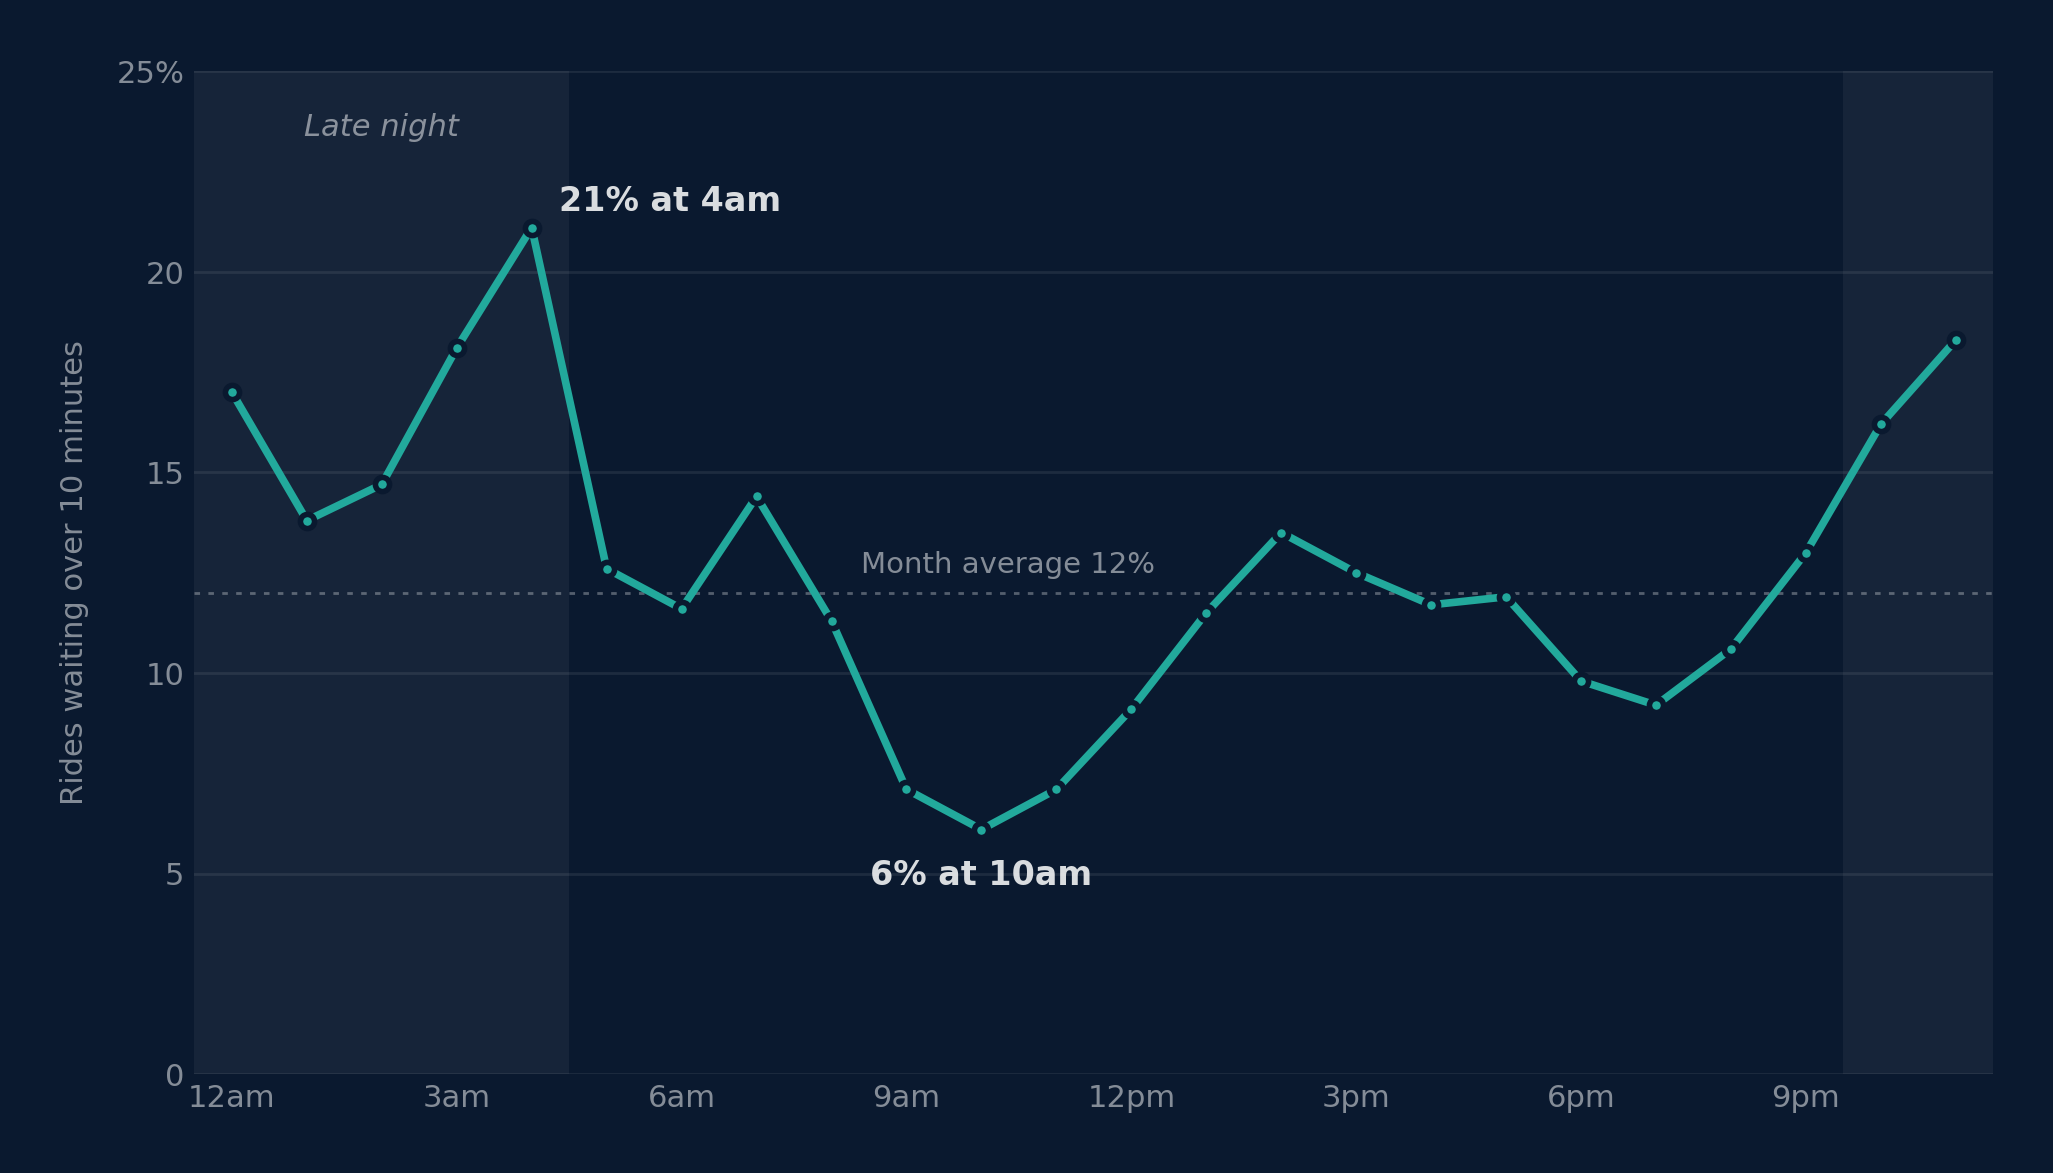

In [7]:
display(Image("charts/by_hour.png", width=800))

Two segments stand out. Late night (22:00 to 04:59) is a fifth of rides and nearly a
third of long waits. Weekday-evening airport pickups are about 1% of rides, but almost four
in ten of them wait over ten minutes.

In [8]:
read("segments")

,segment,trips,long_waits,share_of_trips_pct,share_of_long_waits_pct,long_wait_pct
0,late_night,4371452,737901,21.31,29.90,16.90
1,weekday_evening_airports,248447,96424,1.21,3.90,38.80


## 4. Why is a long wait long?

A wait has two parts: the driver on the way, and the two of them finding each other at the
curb. The fixes are different, so which dominates decides the recommendation.

The expectation going in was that airports would be a curb problem: terminals, pickup
zones, riders who cannot find the car. They are not. At the airports as everywhere else,
around nine-tenths of a long wait is the driver still on the way. **This is a supply
problem.**

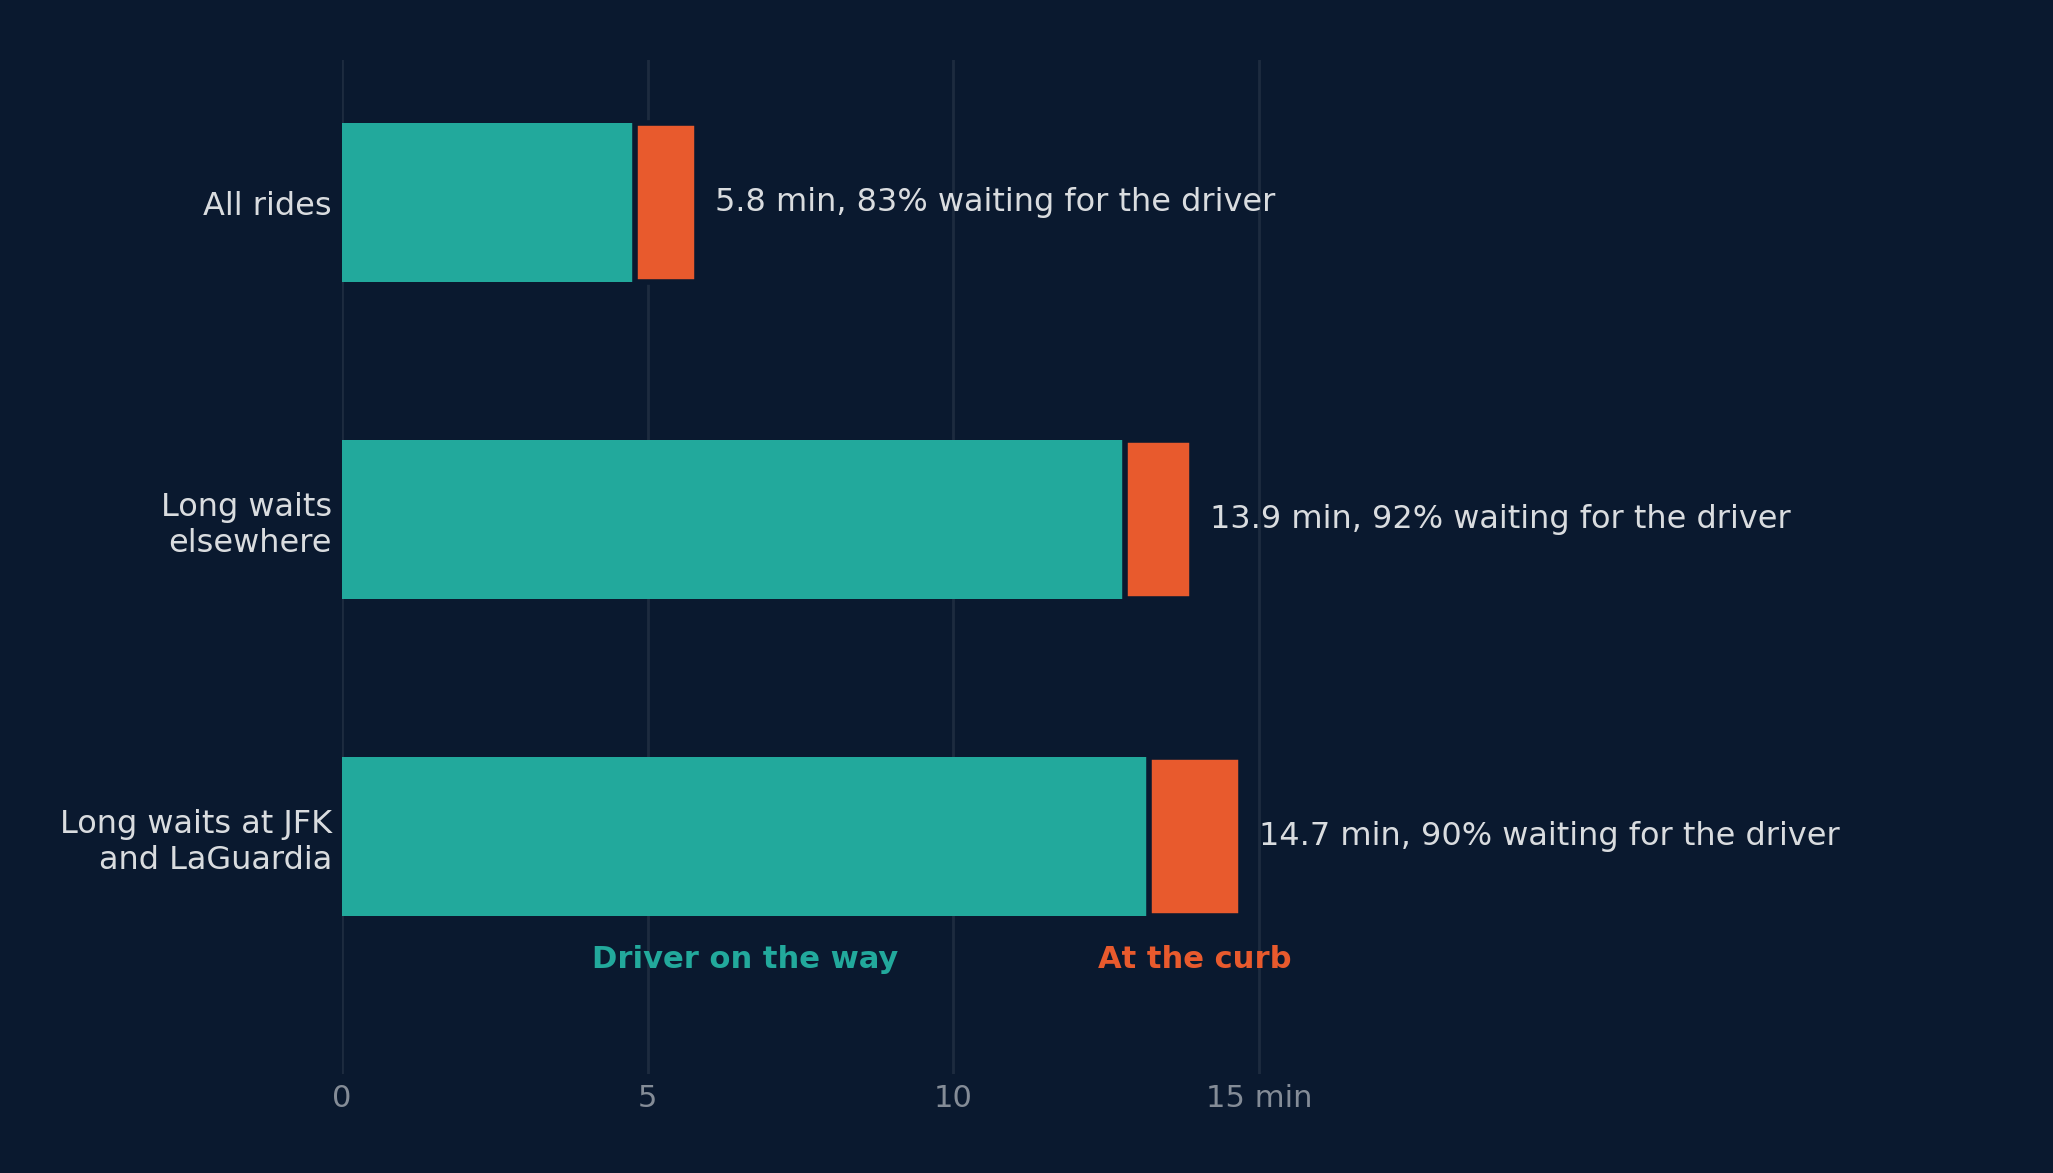

,group_name,trips,to_arrive_min,at_curb_min,to_arrive_share_pct
0,All rides,20388495,4.80,1.00,83.30
1,"Long waits, airports",184530,13.20,1.50,90.00
2,"Long waits, all",2454913,12.90,1.20,91.70
3,"Long waits, city",2270383,12.80,1.10,91.80


In [9]:
display(Image("charts/wait_split.png", width=800))
read("wait_split")

Is it that drivers are paid too little to go there? Not obviously. Pay per hour of trip
time is slightly *higher* in the worst zone-hours, and across zone-hours the long-wait rate
correlates weakly and positively with pay. Pay alone is not the lever: the scheme should
pay for **being available** in the right place at the right hour, not more per ride.

In [10]:
display(read("pay"), read("pay_correlation"))

,top_tenth,pay_per_trip_hour
0,True,65.40
1,False,63.70


,corr_long_wait_rate_vs_pay
0,0.28


## 5. Can a fixed budget reach it?

Rank every zone-hour by how many long waits it produces. The top tenth, 1,235 of 12,356,
hold 44% of all long waits while carrying 30% of rides.

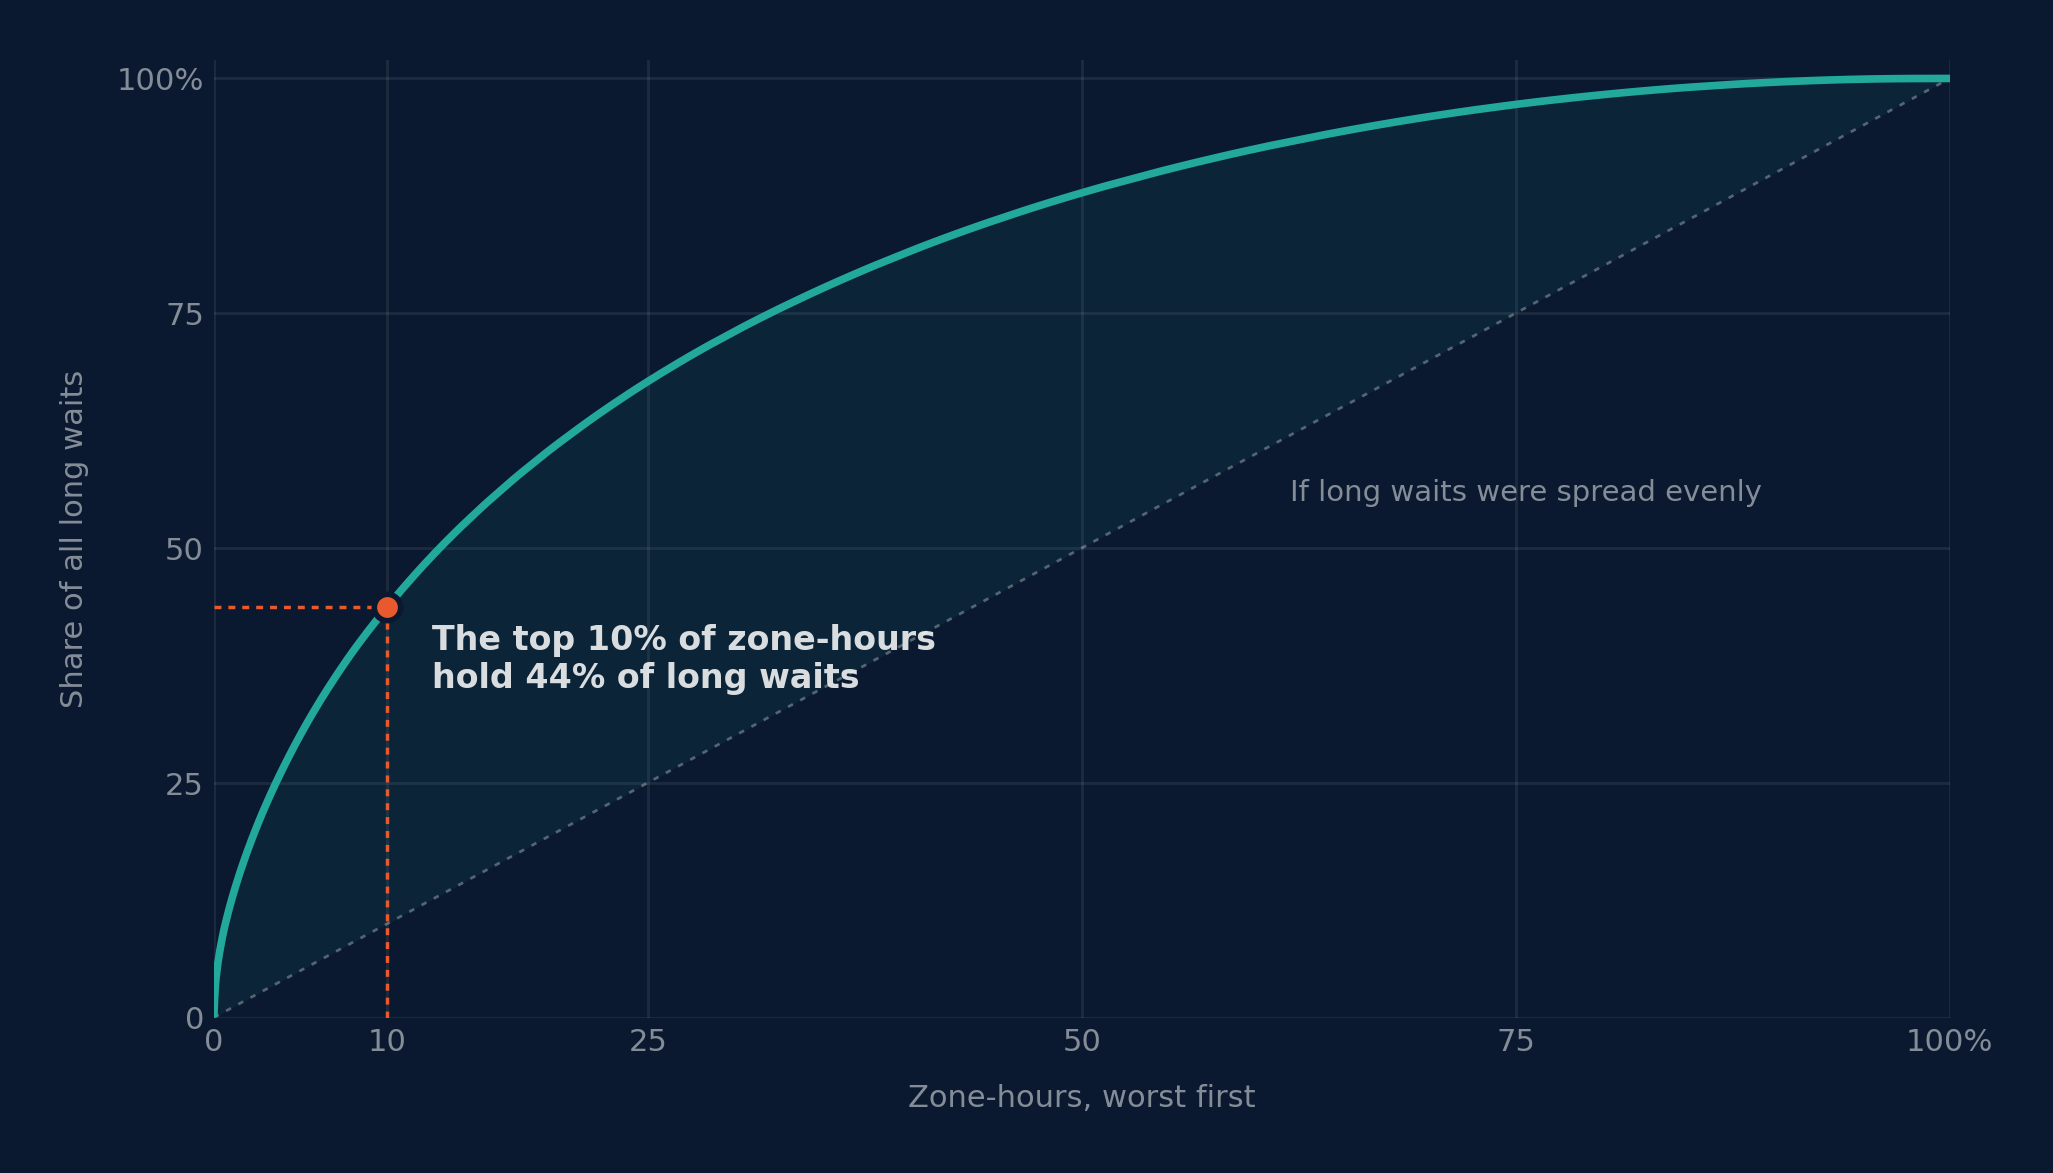

,cells,all_cells,share_of_long_waits_pct,share_of_trips_pct,long_wait_pct,airport_cells,late_night_cells,weekday_cells
0,1235,12356,43.70,30.00,17.60,66,358,902


,borough,cells,long_waits
0,Brooklyn,444,352627
1,Manhattan,386,308052
2,Queens,226,293685
3,Bronx,179,126081


In [11]:
display(Image("charts/concentration.png", width=800))
display(read("top_tenth"), read("top_tenth_by_borough"))

## 6. Does it depend on the ten-minute line?

No. At 8 or 12 minutes the top tenth holds 41 to 46% of long waits, and 93% of the
zone-hours it picks are the same.

In [12]:
read("sensitivity")

,minutes,long_wait_pct,top_tenth_share_pct,same_cells_as_10min_pct
0,8,20.30,41.40,93.00
1,10,12.00,43.70,100.00
2,12,7.40,45.90,93.00


## Recommendation

1. **Concentrate the budget** on the top tenth of zone-hours, starting with late nights and
   weekday-evening airport arrivals.
2. **Pay for availability, not rides.** A guaranteed hourly minimum for drivers online in a
   target zone-hour addresses the part of the wait that is the problem.
3. **Prove it before scaling it.** A four-week test: the scheme switched on in half the
   target zone-hours, chosen at random, the other half left as they are.

**Measured by:** the share of rides waiting over ten minutes in the target zone-hours, the
median time for a driver to arrive, and the cost of each long wait avoided.

## Limits

- One month. Seasonality, holidays and weather are not covered.
- Completed trips only. Riders who gave up are missing, so the worst waits are undercounted.
- Uber and Lyft combined: this is the market, not one operator's own view.
- There is no incentive in the data to measure the effect of one. That is what the test is for.
- Pay per trip-hour leaves out the time drivers spend reaching a pickup or waiting for one.
- Taxi zones are coarse. A real scheme would target finer areas.